# Zero-DCE from scratch: local low-light enhancement

In [44]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import sys, time, json, csv, random, zipfile, itertools
from pathlib import Path
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import color, exposure
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [ ]:
PROJECT = Path(r"C:\Users\0089a\Desktop\DIP_Project\Exp1")

CKPT_DIR = PROJECT / "ckpts"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

RES_DIR = PROJECT / "results"
RES_DIR.mkdir(parents=True, exist_ok=True)

# checking for the folder structure 
# print("Project folder:", PROJECT.resolve())
# print("Checkpoints:", CKPT_DIR.resolve())
# print("Results:", RES_DIR.resolve())

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", dev)

Using device: cuda


In [46]:
LOL_ROOT = PROJECT / "LOL"

TRAIN_DIR = LOL_ROOT / "our485"
EVAL_DIR = LOL_ROOT / "eval15"

print("Training images:", len(list((TRAIN_DIR / "low").iterdir())))
print("Evaluation images:", len(list((EVAL_DIR / "low").iterdir())))
print("Dataset verified.")

Training images: 485
Evaluation images: 15
Dataset verified.


In [47]:
CFG = dict(
    name="base", seed=0, img_size=256, batch_size=4, epochs=100,
    lr=1e-4, wd=1e-4, grad_clip=0.1,
    n_iter=8, n_feat=32,n_val=40, eval_every=5,
    w_spa=1.0, 
    w_exp=10.0, 
    w_col=0.5, 
    w_tv=20.0, 
    exp_target=0.6,
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

In [48]:
class ImageSet(Dataset):
    def __init__(self, paths, size):
        self.data = torch.stack([
            torch.from_numpy(
                np.array(
                    Image.open(p).convert("RGB").resize((size, size), Image.BICUBIC)
                )
            ).permute(2, 0, 1)
            for p in paths
        ])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        return self.data[i].float() / 255.0

def make_data(cfg):
    names = sorted(os.listdir(f"{TRAIN_DIR}/low"))
    rng = np.random.RandomState(1234)
    indices = rng.permutation(len(names))
    val_names = [names[i] for i in indices[:cfg["n_val"]]]
    train_names = [names[i] for i in indices[cfg["n_val"]:]]

    size = cfg["img_size"]

    train = ImageSet([f"{TRAIN_DIR}/low/{n}" for n in train_names], size)
    val_low = ImageSet([f"{TRAIN_DIR}/low/{n}" for n in val_names], size)
    val_high = ImageSet([f"{TRAIN_DIR}/high/{n}" for n in val_names], size)

    return train, val_low, val_high

train_ds, val_low, val_high = make_data(CFG)

print("Training images:", len(train_ds))
print("Validation images:", len(val_low))

Training images: 445
Validation images: 40


## Model, curve mapping, losses

In [ ]:
class DCENet(nn.Module):
    def __init__(self, n_iter=8, n_feat=32):
        super().__init__()

        c = n_feat

        self.c1 = nn.Conv2d(3, c, 3, 1, 1)
        self.c2 = nn.Conv2d(c, c, 3, 1, 1)
        self.c3 = nn.Conv2d(c, c, 3, 1, 1)
        self.c4 = nn.Conv2d(c, c, 3, 1, 1)

        self.c5 = nn.Conv2d(2*c, c, 3, 1, 1)
        self.c6 = nn.Conv2d(2*c, c, 3, 1, 1)
        self.c7 = nn.Conv2d(2*c, 3*n_iter, 3, 1, 1)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0.0, 0.02)
                nn.init.zeros_(m.bias)

    def forward(self, x):

        x1 = F.relu(self.c1(x))
        x2 = F.relu(self.c2(x1))
        x3 = F.relu(self.c3(x2))
        x4 = F.relu(self.c4(x3))

        x5 = F.relu(self.c5(torch.cat([x3, x4], dim=1)))
        x6 = F.relu(self.c6(torch.cat([x2, x5], dim=1)))

        A = torch.tanh(self.c7(torch.cat([x1, x6], dim=1)))

        return A
def apply_curves(x, A):
    for a in torch.split(A, 3, dim=1):
        x = x + a * x * (1 - x)
    return x

In [50]:
def gray(x): return x.mean(1, keepdim=True)

# mean squared distance of local (16x16) average intensity
def loss_exposure(enh, target=0.6, patch=16):
    gray_img = gray(enh)
    local_mean = F.avg_pool2d(gray_img, patch)

    return ((local_mean - target) ** 2).mean()

#channel means should be closer 
def loss_color(enh):
    img = enh.mean((2, 3))
    r, g, b = img[:, 0], img[:, 1], img[:, 2]

    return ((r-g)**2 + (r-b)**2 + (g-b)**2).mean()

# Neighbouring-region differences of the enhanced image should match those of the input.
def loss_spatial(enh, orig, pool=4):
    enh_gray = F.avg_pool2d(gray(enh), pool)
    orig_gray = F.avg_pool2d(gray(orig), pool)

    enh_dx = enh_gray[..., 1:] - enh_gray[..., :-1]
    orig_dx = orig_gray[..., 1:] - orig_gray[..., :-1]

    enh_dy = enh_gray[..., 1:, :] - enh_gray[..., :-1, :]
    orig_dy = orig_gray[..., 1:, :] - orig_gray[..., :-1, :]

    loss_x = ((enh_dx.abs() - orig_dx.abs())**2).mean()
    loss_y = ((enh_dy.abs() - orig_dy.abs())**2).mean()

    return loss_x + loss_y

#total variation of the curve-parameter maps.
def loss_tv(A):
    dx = F.pad(A[..., 1:] - A[..., :-1], (0, 1, 0, 0))
    dy = F.pad(A[..., 1:, :] - A[..., :-1, :], (0, 0, 0, 1))
    return ((dx.abs() + dy.abs()) ** 2).mean()

def total_loss(x, enh, A, cfg):
    spa = loss_spatial(enh, x)
    exp = loss_exposure(enh, cfg["exp_target"])
    col = loss_color(enh)
    tv = loss_tv(A)

    total = (
        cfg["w_spa"] * spa +
        cfg["w_exp"] * exp +
        cfg["w_col"] * col +
        cfg["w_tv"] * tv
    )

    parts = {
        "spa": spa.item(),
        "exp": exp.item(),
        "col": col.item(),
        "tv": tv.item()
    }

    return total, parts

## 3. Training

In [ ]:
@torch.no_grad()
def val_psnr(model, low, high):
    model.eval()

    x = low.data.float().to(dev) / 255.0
    y = high.data.float().to(dev) / 255.0

    A = model(x)

    enhanced = apply_curves(x, A)
    enhanced = enhanced.clamp(0, 1)

    mse = ((enhanced - y) ** 2).mean(dim=(1, 2, 3))
    mse = mse.clamp_min(1e-10)

    psnr = 10 * torch.log10(1 / mse)

    model.train()
    return psnr.mean().item()

def train(cfg, resume=True):
    set_seed(cfg["seed"])

    # datasets
    if cfg["img_size"] == CFG["img_size"]:
        tr, vl, vh = train_ds, val_low, val_high
    else:
        tr, vl, vh = make_data(cfg)

    model = DCENet(cfg["n_iter"], cfg["n_feat"]).to(dev)

    opt = torch.optim.Adam(model.parameters(),lr=cfg["lr"],weight_decay=cfg["wd"])
    path = f"{CKPT_DIR}/{cfg['name']}.pt"

    start_epoch = 0
    hist = []

    # resume if there is checkpoint
    if resume and os.path.exists(path):
        ck = torch.load(path, map_location=dev, weights_only=False)

        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])

        start_epoch = ck["epoch"] + 1
        hist = ck["hist"]

        print("Resuming from epoch:", start_epoch)

    loader = DataLoader(tr,batch_size=cfg["batch_size"],shuffle=True,drop_last=True)

    model.train()
    start_time = time.time()

    for ep in range(start_epoch, cfg["epochs"]):

        total_loss_value = 0
        spa_value = 0
        exp_value = 0
        col_value = 0
        tv_value = 0

        batches = 0

        for x in loader:
            x = x.to(dev)

            A = model(x)
            enhanced = apply_curves(x, A)

            loss, parts = total_loss(x, enhanced, A, cfg)

            opt.zero_grad()
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(),cfg["grad_clip"])

            opt.step()

            total_loss_value += loss.item()
            spa_value += parts["spa"]
            exp_value += parts["exp"]
            col_value += parts["col"]
            tv_value += parts["tv"]

            batches += 1

        rec = {
            "epoch": ep,
            "total": total_loss_value / batches,
            "spa": spa_value / batches,
            "exp": exp_value / batches,
            "col": col_value / batches,
            "tv": tv_value / batches
        }

        if (ep + 1) % cfg["eval_every"] == 0 or ep == cfg["epochs"] - 1:
            rec["val_psnr"] = val_psnr(model, vl, vh)
            torch.save({
                "model": model.state_dict(),
                "opt": opt.state_dict(),
                "epoch": ep,
                "hist": hist + [rec],
                "cfg": cfg
            }, path)

            print(
                f"[{cfg['name']}] "
                f"Epoch {ep+1}/{cfg['epochs']} "
                f"Loss: {rec['total']:.4f} "
                f"PSNR: {rec['val_psnr']:.2f} dB"
            )
        hist.append(rec)
    with open(f"{RES_DIR}/{cfg['name']}_hist.json", "w") as f:
        json.dump(hist, f)

    return model, hist

In [52]:
# training the model
model, hist = train(CFG, resume=True)

Resuming from epoch: 100


## Evaluation (one metric code path for every method)

In [ ]:
def load_rgb(p): return np.array(Image.open(p).convert("RGB"))

EVAL_NAMES = sorted(os.listdir(f"{EVAL_DIR}/low"))
EVAL_LOW = [load_rgb(f"{EVAL_DIR}/low/{n}") for n in EVAL_NAMES]
EVAL_HIGH = [load_rgb(f"{EVAL_DIR}/high/{n}") for n in EVAL_NAMES]

def evaluate_fn(enhance):
    psnr_values = []
    ssim_values = []
    outputs = []

    for low, high in zip(EVAL_LOW, EVAL_HIGH):
        enhanced = enhance(low)
        outputs.append(enhanced)

        psnr_values.append(peak_signal_noise_ratio(high, enhanced, data_range=255))
        ssim_values.append(structural_similarity(high, enhanced,channel_axis=-1,data_range=255))

    scores = {"psnr": np.mean(psnr_values),"ssim": np.mean(ssim_values)}
    return scores, outputs


@torch.no_grad()
def make_enhancer(model):
    model.eval()

    def enhance(img):
        x = torch.from_numpy(img).permute(2, 0, 1)
        x = x.unsqueeze(0).float().to(dev) / 255.0
        
        A = model(x)
        output = apply_curves(x, A).clamp(0, 1)

        output = output.squeeze(0).permute(1, 2, 0)
        output = (output.detach().cpu().numpy() * 255).round()

        return output.astype(np.uint8)
    return enhance


def load_model(name):
    path = f"{CKPT_DIR}/{name}.pt"

    checkpoint = torch.load(path,map_location=dev,weights_only=False)

    cfg = checkpoint["cfg"]
    model = DCENet(cfg["n_iter"], cfg["n_feat"]).to(dev)

    model.load_state_dict(checkpoint["model"])
    return model


In [54]:
enhance = make_enhancer(model)
scores, outs = evaluate_fn(enhance)

# Evaluate original low-light images
input_scores, _ = evaluate_fn(lambda img: img)

print("Input :", input_scores)
print("Ours  :", scores)

Input : {'psnr': np.float64(7.773328136578076), 'ssim': np.float64(0.1914046211289365)}
Ours  : {'psnr': np.float64(11.622667976761893), 'ssim': np.float64(0.4148518741711822)}


Resuming from epoch: 30
Resuming from epoch: 30
Resuming from epoch: 30


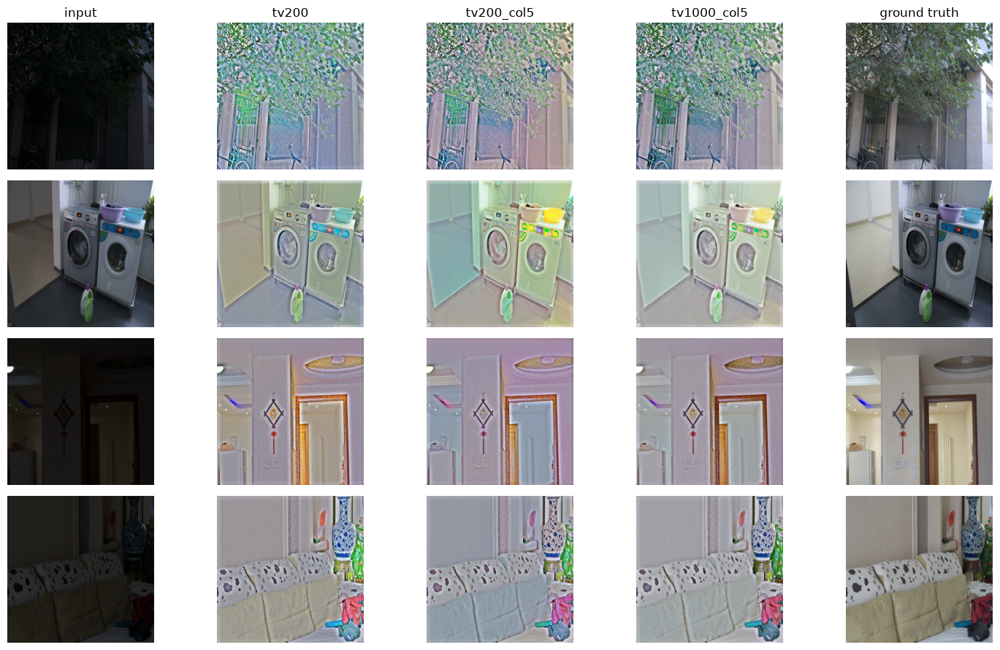

In [55]:
SWEEP = {
    "tv200":         dict(w_tv=200.0),
    "tv200_col5":    dict(w_tv=200.0, w_col=5.0),
    "tv1000_col5":   dict(w_tv=1000.0, w_col=5.0),
}
for k, o in SWEEP.items():
    train({**CFG, **o, "name": f"sweep_{k}", "epochs": 30})

vi  = [val_low.data[i].permute(1, 2, 0).numpy() for i in range(4)]
vg  = [val_high.data[i].permute(1, 2, 0).numpy() for i in range(4)]
enh = {k: make_enhancer(load_model(f"sweep_{k}")) for k in SWEEP}
cols = ["input"] + list(SWEEP) + ["ground truth"]
fig, ax = plt.subplots(4, len(cols), figsize=(3 * len(cols), 9))
for r in range(4):
    for c, im in enumerate([vi[r]] + [enh[k](vi[r]) for k in SWEEP] + [vg[r]]):
        ax[r, c].imshow(im); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(cols[c])
plt.tight_layout(); plt.show()

In [56]:
yh = val_high.data.float() / 255
def stats(t):
    g = t.mean(1, keepdim=True)
    return {
        "mean": round(t.mean().item(), 3),
        "contrast": round(g.std((1, 2, 3)).mean().item(), 3),
        "patch_std": round(F.avg_pool2d(g, 16).std((1, 2, 3)).mean().item(), 3),
        "RGB": [round(v, 3) for v in t.mean((0, 2, 3)).tolist()],
        "col": round(loss_color(t).item(), 4)
    }
@torch.no_grad()
def run_stats(name):
    model = load_model(name).eval()
    x = val_low.data.float().div(255).to(dev)

    out = apply_curves(x, model(x)).clamp(0, 1).cpu()
    mse = ((out - yh) ** 2).mean((1, 2, 3)).clamp_min(1e-10)
    psnr = (10 * torch.log10(1 / mse)).mean().item()

    return {**stats(out), "psnr": round(psnr, 2)}

BASE = {
    **CFG,
    "w_tv": 200.0,
    "w_col": 0.5,
    "w_spa": 1.0,
    "w_exp": 1.0,
    "exp_target": 0.45,
    "n_iter": 8,
    "epochs": 30,
    "seed": 0
}

ARRAYS = {
    "seed":       [1, 2],
    "w_exp":      [0.5, 0.75, 1.5],
    "exp_target": [0.40, 0.50, 0.55],
    "w_tv":       [400.0, 1000.0, 5000.0],
    "w_spa":      [0.5, 2.0]
}

#oat = vary one parameter; grid = every combination
MODE = "grid" 
MAX_RUNS = 150

def make_plan(arrays, mode):
    keys = list(arrays)
    if mode == "oat":
        return [
            {k: v}
            for k, values in arrays.items()
            for v in values
            if v != BASE[k]
        ]
    plan = [dict(zip(keys, values))for values in itertools.product(*(arrays[k] for k in keys))]

    return [
        p for p in plan
        if any(BASE[k] != v for k, v in p.items())
    ]

def plan_name(params):
    return "s5_" + "_".join(f"{k}{v}" for k, v in params.items())

PLAN = make_plan(ARRAYS, MODE)
if len(PLAN) > MAX_RUNS:
    print(f"Keeping {MAX_RUNS} of {len(PLAN)} planned runs")
    PLAN = PLAN[:MAX_RUNS]
print("Planned experiments:", len(PLAN))

Planned experiments: 108


In [ ]:
RUN = False
# Set this to True when need to train the model

if RUN:
    for params in PLAN:
        train({**BASE,**params,"name": plan_name(params)})

In [58]:
def sweep_table(plan, base_name="sweep4_t45_w1"):
    rows = [{"run": "base", **run_stats(base_name)}]
    for params in plan:
        name = plan_name(params)
        path = f"{CKPT_DIR}/{name}.pt"

        if os.path.exists(path):
            rows.append({"run": name[3:],**run_stats(name)})

    base_psnr = rows[0]["psnr"]

    seed_noise = [
        abs(r["psnr"] - base_psnr)
        for r in rows if r["run"].startswith("seed")
    ]

    noise = max(seed_noise) if seed_noise else None
    print("PSNR noise from seeds:", noise if noise is not None else "not measured")

    print(f"{'run':22s} {'PSNR':>6s} {'dPSNR':>6s} {'mean':>6s} {'contr':>6s} {'p_std':>6s} {'col':>7s}")

    for r in rows:
        d = r["psnr"] - base_psnr
        star = "*" if noise is not None and r["run"] != "base" and abs(d) > noise else " "

        print(
            f"{r['run']:22s} {r['psnr']:6.2f} "
            f"{d:+6.2f}{star}{r['mean']:6.3f} "
            f"{r['contrast']:6.3f} {r['patch_std']:6.3f} "
            f"{r['col']:7.4f}"
        )

    fields = ["run", "psnr", "mean", "contrast", "patch_std", "col", "RGB"]
    with open(f"{RES_DIR}/sweep5_table.csv", "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    return rows

In [59]:
# rows = sweep_table(PLAN)

In [82]:
def show_runs(names, idx=(0, 1, 2, 3)):
    VL = [
        val_low.data[i].permute(1, 2, 0).numpy()
        for i in range(len(val_low))]

    VH = [
        val_high.data[i].permute(1, 2, 0).numpy()
        for i in range(len(val_high))]

    enh = {
        n: make_enhancer(load_model(n))
        for n in names}

    cols = ["input"] + [n.replace("s5_", "") for n in names] + ["ground truth"]

    fig, ax = plt.subplots(len(idx), len(cols),figsize=(2.6 * len(cols), 2.3 * len(idx)),squeeze=False)

    for r, i in enumerate(idx):
        imgs = [VL[i]] + [enh[n](VL[i]) for n in names] + [VH[i]]
        for c, im in enumerate(imgs):
            ax[r, c].imshow(im)
            ax[r, c].axis("off")
            if r == 0:
                ax[r, c].set_title(cols[c], fontsize=7)
    plt.tight_layout()
    plt.show()

s5_seed1_w_exp0.5_exp_target0.4_w_tv1000.0_w_spa0.5 FOUND
s5_seed1_w_exp0.5_exp_target0.4_w_tv1000.0_w_spa2.0 FOUND
s5_seed1_w_exp0.5_exp_target0.5_w_tv400.0_w_spa0.5 FOUND
s5_seed1_w_exp0.5_exp_target0.5_w_tv400.0_w_spa2.0 FOUND
s5_seed1_w_exp0.5_exp_target0.4_w_tv5000.0_w_spa2.0 FOUND
s5_seed1_w_exp0.75_exp_target0.4_w_tv5000.0_w_spa2.0 FOUND
s5_seed2_w_exp0.5_exp_target0.4_w_tv5000.0_w_spa0.5 FOUND


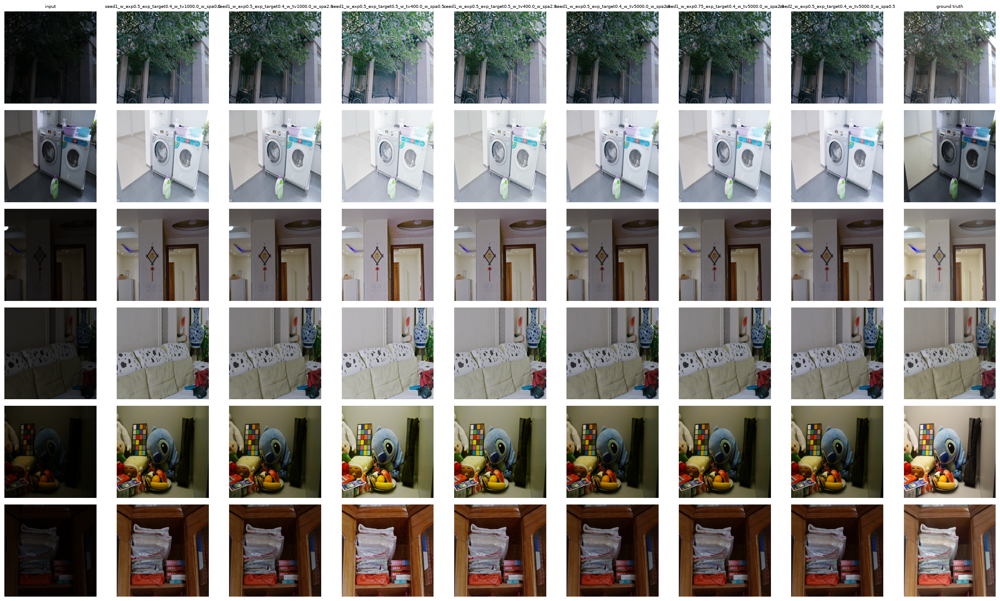

In [61]:
CANDIDATES = [
    {"seed": 1, "w_exp": 0.5, "exp_target": 0.4, "w_tv": 1000.0, "w_spa": 0.5},
    {"seed": 1, "w_exp": 0.5, "exp_target": 0.4, "w_tv": 1000.0, "w_spa": 2.0},
    {"seed": 1, "w_exp": 0.5, "exp_target": 0.5, "w_tv": 400.0, "w_spa": 0.5},
    {"seed": 1, "w_exp": 0.5, "exp_target": 0.5, "w_tv": 400.0, "w_spa": 2.0},
    {"seed": 1, "w_exp": 0.5, "exp_target": 0.4, "w_tv": 5000.0, "w_spa": 2.0},
    {"seed": 1, "w_exp": 0.75, "exp_target": 0.4, "w_tv": 5000.0, "w_spa": 2.0},
    {"seed": 2, "w_exp": 0.5, "exp_target": 0.4, "w_tv": 5000.0, "w_spa": 0.5}
]
candidate_names = [plan_name(c) for c in CANDIDATES]
available = []

for name in candidate_names:
    path = os.path.join(CKPT_DIR, name + ".pt")
    if os.path.exists(path):
        print(name, "FOUND")
        available.append(name)
    else:
        print(name, "MISSING")

show_runs( available,idx=(0, 1, 2, 3, 4, 5))

mean alpha per iteration: [0.406, 0.4, 0.39, 0.372, 0.36, 0.348, 0.338, 0.331]
mean brightness per step: [0.059, 0.079, 0.103, 0.135, 0.172, 0.216, 0.268, 0.326, 0.389]


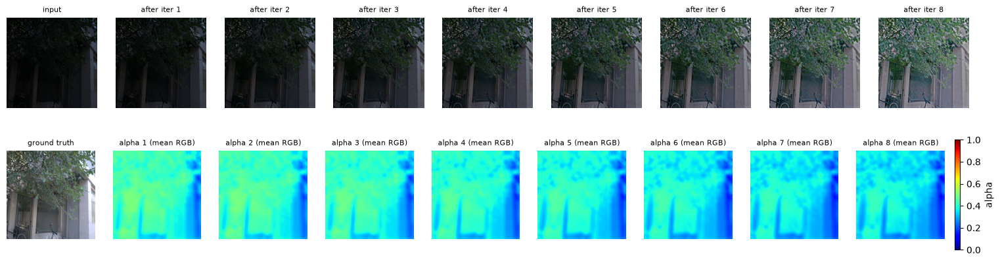

mean alpha per iteration: [0.378, 0.372, 0.362, 0.345, 0.333, 0.322, 0.312, 0.305]
mean brightness per step: [0.074, 0.097, 0.127, 0.163, 0.206, 0.257, 0.314, 0.376, 0.443]


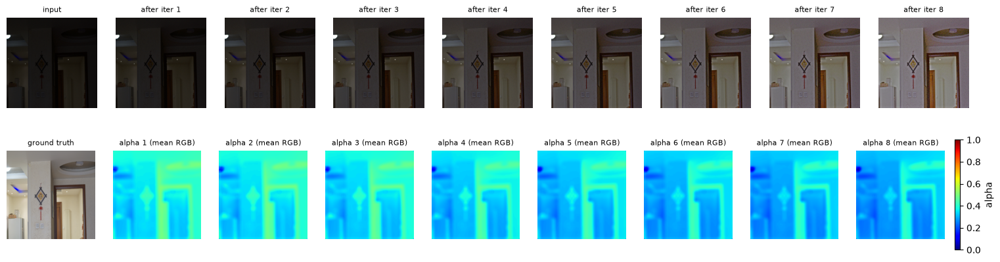

mean alpha per iteration: [0.425, 0.419, 0.409, 0.39, 0.379, 0.366, 0.356, 0.349]
mean brightness per step: [0.052, 0.07, 0.092, 0.121, 0.155, 0.195, 0.242, 0.294, 0.352]


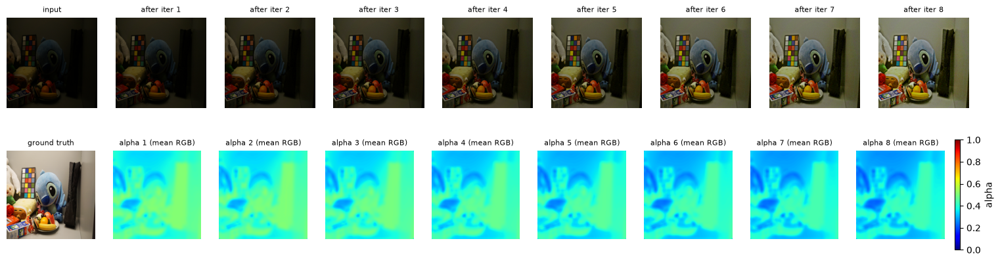

mean alpha per iteration: [0.451, 0.444, 0.433, 0.415, 0.403, 0.39, 0.379, 0.372]
mean brightness per step: [0.031, 0.044, 0.062, 0.085, 0.115, 0.154, 0.201, 0.257, 0.321]


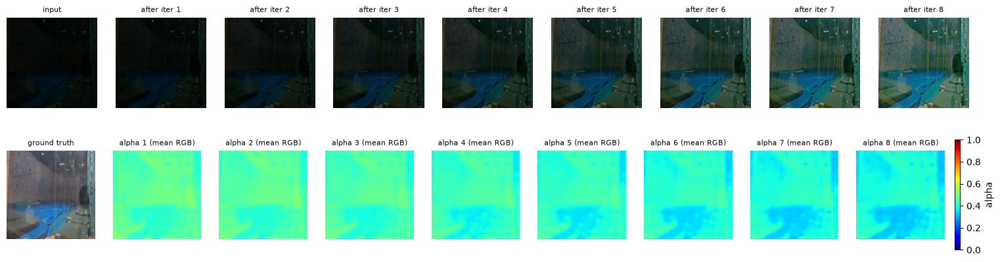

mean alpha per iteration: [0.486, 0.479, 0.468, 0.45, 0.437, 0.425, 0.413, 0.406]
mean brightness per step: [0.014, 0.02, 0.029, 0.041, 0.058, 0.079, 0.107, 0.141, 0.183]


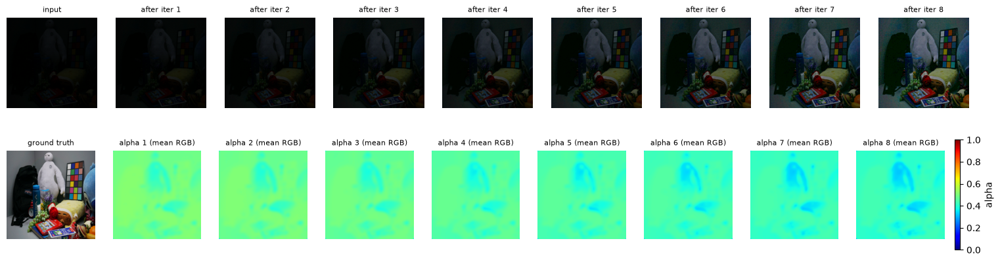

mean alpha per iteration: [0.425, 0.419, 0.409, 0.391, 0.379, 0.367, 0.356, 0.35]
mean brightness per step: [0.046, 0.063, 0.085, 0.115, 0.152, 0.197, 0.251, 0.314, 0.384]


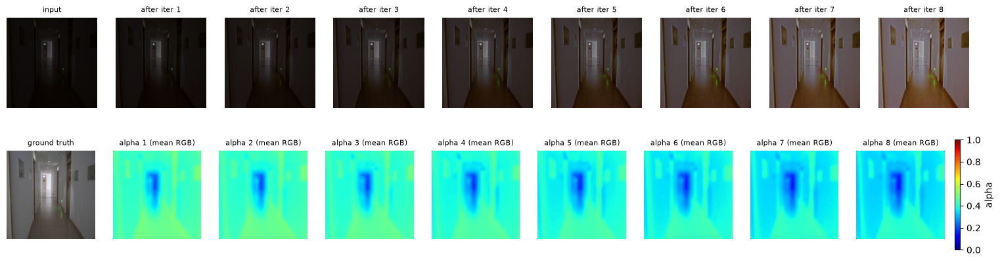

mean alpha per iteration: [0.413, 0.407, 0.396, 0.378, 0.367, 0.355, 0.344, 0.337]
mean brightness per step: [0.057, 0.075, 0.098, 0.126, 0.16, 0.2, 0.246, 0.298, 0.355]


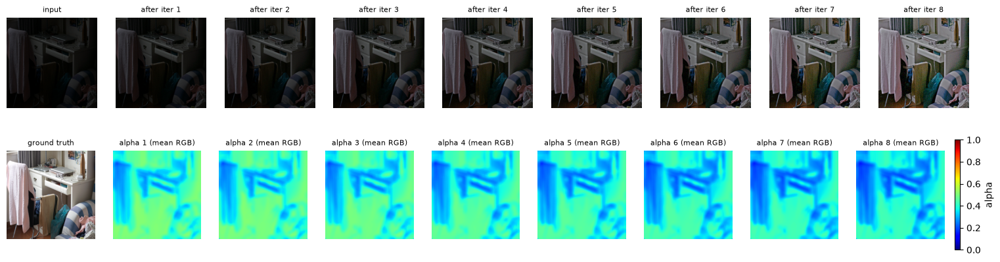

mean alpha per iteration: [0.442, 0.436, 0.425, 0.407, 0.395, 0.383, 0.372, 0.365]
mean brightness per step: [0.032, 0.045, 0.063, 0.086, 0.116, 0.154, 0.2, 0.255, 0.318]


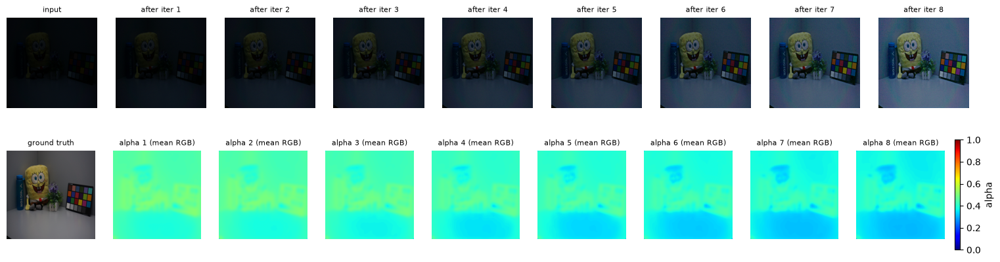

In [ ]:
@torch.no_grad()
def curve_report(name, img_u8, gt_u8=None, ch=1):
    model = load_model(name).eval()
    x = torch.from_numpy(img_u8).permute(2, 0, 1)[None].float().div(255).to(dev)

    A = model(x)
    alphas = torch.split(A, 3, dim=1)
    n = len(alphas)

#applying curves over image
    steps = [x]
    for a in alphas:
        o = steps[-1]
        steps.append(o + a * o * (1 - o))
    to_img = lambda t: t[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()

    print("mean alpha per iteration:", [round(a.mean().item(), 3) for a in alphas])
    print("mean brightness per step:", [round(s.mean().item(), 3) for s in steps])
    
    fig, ax = plt.subplots(2, n + 1, figsize=(2.1 * (n + 1), 4.8))
    ax[0, 0].imshow(to_img(steps[0]))
    ax[0, 0].set_title("input", fontsize=8)

    if gt_u8 is not None:
        ax[1, 0].imshow(gt_u8)
        ax[1, 0].set_title("ground truth", fontsize=8)

    for k in range(1, n + 1):
        ax[0, k].imshow(to_img(steps[k]))
        ax[0, k].set_title(f"after iter {k}", fontsize=8)
        im = ax[1, k].imshow(alphas[k - 1][0].mean(0).cpu().numpy(),cmap="jet", vmin=0, vmax=1)
        ax[1, k].set_title(f"alpha {k} (mean RGB)", fontsize=8)

    for a_ in ax.ravel():
        a_.axis("off")
    fig.colorbar(im, ax=ax[1, :], fraction=0.015, pad=0.01, label="alpha")
    plt.show()

for i in range(0, 15, 2):
    curve_report(
        "sweep4_t45_w1",
        val_low.data[i].permute(1, 2, 0).numpy(),
        val_high.data[i].permute(1, 2, 0).numpy()
    )

## Ablation Study

In [ ]:
SELECTED = {
    "seed": 1,
    "w_exp": 0.5,
    "exp_target": 0.5,
    "w_tv": 400.0,
    "w_spa": 2.0,
}

ABLATION_BASE = {
    **BASE,
    **SELECTED,
    "name": "ablation_full",
}

ABLATIONS = {
    "full": {},
    "no_spatial": {"w_spa": 0.0},
    "no_exposure": {"w_exp": 0.0},
    "no_color": {"w_col": 0.0},
    "no_tv": {"w_tv": 0.0}
}

In [64]:
ABLATION_CONFIGS = {
    label: {
        **ABLATION_BASE,
        **changes,
        "name": f"ablation_{label}",
    }
    for label, changes in ABLATIONS.items()
}

for label, cfg in ABLATION_CONFIGS.items():
    print(f"\nTraining: {label}")
    print({
        k: cfg[k]
        for k in [
            "seed", "w_spa", "w_exp",
            "w_col", "w_tv", "exp_target",
            "n_iter", "epochs"
        ]
    })
    model, hist = train(cfg, resume=True)

print("\nAll ablation experiments completed.")


Training: full
{'seed': 1, 'w_spa': 2.0, 'w_exp': 0.5, 'w_col': 0.5, 'w_tv': 400.0, 'exp_target': 0.5, 'n_iter': 8, 'epochs': 30}
Resuming from epoch: 30

Training: no_spatial
{'seed': 1, 'w_spa': 0.0, 'w_exp': 0.5, 'w_col': 0.5, 'w_tv': 400.0, 'exp_target': 0.5, 'n_iter': 8, 'epochs': 30}
Resuming from epoch: 30

Training: no_exposure
{'seed': 1, 'w_spa': 2.0, 'w_exp': 0.0, 'w_col': 0.5, 'w_tv': 400.0, 'exp_target': 0.5, 'n_iter': 8, 'epochs': 30}
Resuming from epoch: 30

Training: no_color
{'seed': 1, 'w_spa': 2.0, 'w_exp': 0.5, 'w_col': 0.0, 'w_tv': 400.0, 'exp_target': 0.5, 'n_iter': 8, 'epochs': 30}
Resuming from epoch: 30

Training: no_tv
{'seed': 1, 'w_spa': 2.0, 'w_exp': 0.5, 'w_col': 0.5, 'w_tv': 0.0, 'exp_target': 0.5, 'n_iter': 8, 'epochs': 30}
Resuming from epoch: 30

All ablation experiments completed.


In [65]:
@torch.no_grad()
def ablation_metrics(name):

    model = load_model(name).eval()

    x = val_low.data.float().to(dev) / 255.0
    y = val_high.data.float().to(dev) / 255.0

    A = model(x)
    enhanced = apply_curves(x, A).clamp(0, 1)

    mse = ((enhanced - y) ** 2).mean((1, 2, 3))
    psnr = (10 * torch.log10(1 / mse.clamp_min(1e-10))).mean()

    spa = loss_spatial(enhanced, x)
    exp = loss_exposure(enhanced, ABLATION_BASE["exp_target"])
    col = loss_color(enhanced)
    tv = loss_tv(A)

    g = gray(enhanced)

    return {
        "run": name,
        "PSNR": psnr.item(),
        "spatial": spa.item(),
        "exposure": exp.item(),
        "color": col.item(),
        "TV": tv.item(),
        "brightness": enhanced.mean().item(),
        "contrast": g.std().item(),
        "RGB_R": enhanced[:, 0].mean().item(),
        "RGB_G": enhanced[:, 1].mean().item(),
        "RGB_B": enhanced[:, 2].mean().item()
    }

In [66]:
ablation_rows = []
ABLATION_NAMES = list(ABLATIONS.keys())

for label in ABLATION_NAMES:
    name = f"ablation_{label}"
    row = ablation_metrics(name)
    row["experiment"] = label
    ablation_rows.append(row)
ablation_df = pd.DataFrame(ablation_rows)
ablation_df = ablation_df[
    [
        "experiment",
        "PSNR",
        "brightness",
        "contrast",
        "spatial",
        "exposure",
        "color",
        "TV",
        "RGB_R",
        "RGB_G",
        "RGB_B"
    ]
]
display(ablation_df.round(4))
ablation_df.to_csv(RES_DIR / "four_loss_ablation.csv",index=False)

,experiment,PSNR,brightness,contrast,spatial,exposure,color,TV,RGB_R,RGB_G,RGB_B
0,full,17.6373,0.4017,0.2117,0.0054,0.0475,0.0160,0.000,0.4082,0.4040,0.3928
1,no_spatial,18.3343,0.5023,0.2325,0.0082,0.0446,0.0239,0.000,0.5089,0.5039,0.4941
2,no_exposure,7.3128,0.0574,0.0667,0.0000,0.1998,0.0004,0.000,0.0579,0.0583,0.0561
3,no_color,7.3012,0.4469,0.1120,0.0018,0.0127,1.4016,0.000,0.3790,0.9538,0.0080
4,no_tv,14.2923,0.4567,0.0983,0.0012,0.0071,0.0174,0.002,0.4567,0.4658,0.4476


ablation_full: FOUND
ablation_no_spatial: FOUND
ablation_no_exposure: FOUND
ablation_no_color: FOUND
ablation_no_tv: FOUND


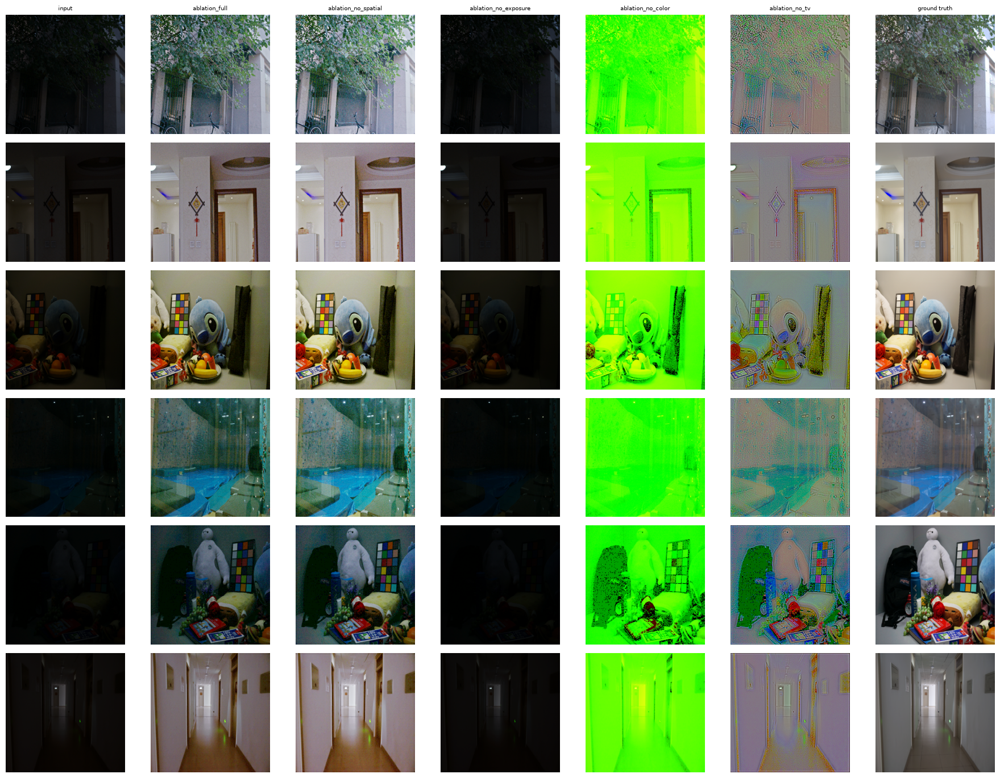

In [67]:
ABLATION_RUNS = [
    "ablation_full",
    "ablation_no_spatial",
    "ablation_no_exposure",
    "ablation_no_color",
    "ablation_no_tv",
]

available = []

for name in ABLATION_RUNS:
    path = CKPT_DIR / f"{name}.pt"

    if path.exists():
        print(f"{name}: FOUND")
        available.append(name)
    else:
        print(f"{name}: MISSING")

show_runs(available, idx=(0,2,4,6,8,10))
# show_runs(available, idx=[0])

In [68]:
ablation_eval = {}

for name in ABLATION_RUNS:
    model = load_model(name)
    enhance = make_enhancer(model)

    scores, outputs = evaluate_fn(enhance)
    ablation_eval[name] = scores

    print(
        f"{name:25s} | "
        f"PSNR: {scores['psnr']:.4f} | "
        f"SSIM: {scores['ssim']:.4f}"
    )

ablation_full             | PSNR: 18.0888 | SSIM: 0.5678
ablation_no_spatial       | PSNR: 17.2613 | SSIM: 0.5411
ablation_no_exposure      | PSNR: 7.4943 | SSIM: 0.1577
ablation_no_color         | PSNR: 7.2145 | SSIM: 0.3207
ablation_no_tv            | PSNR: 13.5345 | SSIM: 0.3954


In [69]:
ablation_eval_df = pd.DataFrame.from_dict(
    ablation_eval,
    orient="index"
)

ablation_eval_df.index.name = "experiment"

display(ablation_eval_df.round(4))

,psnr,ssim
experiment,,
ablation_full,18.0888,0.5678
ablation_no_spatial,17.2613,0.5411
ablation_no_exposure,7.4943,0.1577
ablation_no_color,7.2145,0.3207
ablation_no_tv,13.5345,0.3954


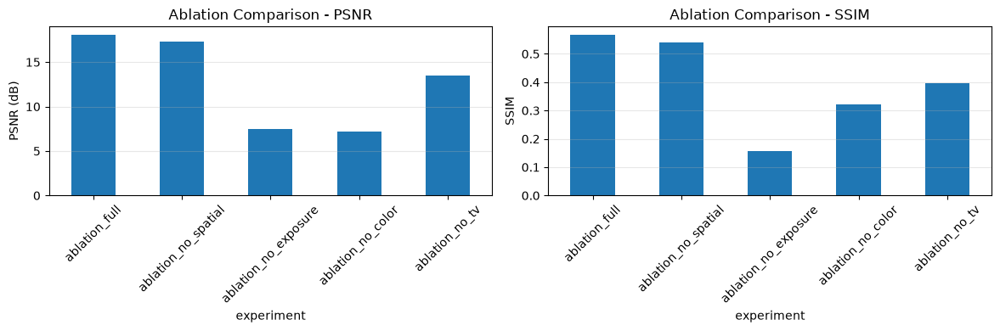

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ablation_eval_df["psnr"].plot(
    kind="bar", ax=axes[0], title="Ablation Comparison - PSNR"
)

ablation_eval_df["ssim"].plot(
    kind="bar", ax=axes[1], title="Ablation Comparison - SSIM"
)

axes[0].set_ylabel("PSNR (dB)")
axes[1].set_ylabel("SSIM")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

ablation_eval_df.to_csv(
    RES_DIR / "ablation_psnr_ssim.csv"
)

## Implementation Classical Methods ie. HE, CLAHE, Gamma Correction

In [ ]:
# 1. Histogram Equalization

def apply_he(img):
    rgb = img.astype(np.float32) / 255.0
    ycbcr = color.rgb2ycbcr(rgb)
    Y = ycbcr[:, :, 0]
    ycbcr[:, :, 0] = exposure.equalize_hist(Y) * 255.0
    output = color.ycbcr2rgb(ycbcr)

    return (np.clip(output, 0, 1) * 255).round().astype(np.uint8)

# 2. CLAHE
def apply_clahe(img):
    rgb = img.astype(np.float32) / 255.0

    lab = color.rgb2lab(rgb)
    L = lab[:, :, 0] / 100.0

    lab[:, :, 0] = exposure.equalize_adapthist(
        L,
        kernel_size=32,
        clip_limit=0.02
    ) * 100.0

    output = color.lab2rgb(lab)
    return (np.clip(output, 0, 1) * 255).round().astype(np.uint8)


# 3. Gamma Correction
def apply_gamma(img, gamma=0.6):
    x = img.astype(np.float32) / 255.0
    output = np.power(x, gamma)

    return (np.clip(output, 0, 1) * 255).round().astype(np.uint8)

In [72]:
classical_methods = {
    "HE": apply_he,
    "CLAHE": apply_clahe,
    "Gamma": apply_gamma
}

# Load the full Zero-DCE model
full_model = load_model("ablation_full")
zero_dce = make_enhancer(full_model)

all_methods = {"Zero-DCE": zero_dce,**classical_methods}

classical_results = {}

for name, enhance in all_methods.items():
    scores, outputs = evaluate_fn(enhance)

    classical_results[name] = {
        "PSNR": scores["psnr"],
        "SSIM": scores["ssim"]
    }

    print(f"{name:12s} | "f"PSNR: {scores['psnr']:.4f} | "f"SSIM: {scores['ssim']:.4f}")

Zero-DCE     | PSNR: 18.0888 | SSIM: 0.5678
HE           | PSNR: 13.2924 | SSIM: 0.3883
CLAHE        | PSNR: 12.4817 | SSIM: 0.3903
Gamma        | PSNR: 10.6739 | SSIM: 0.4769


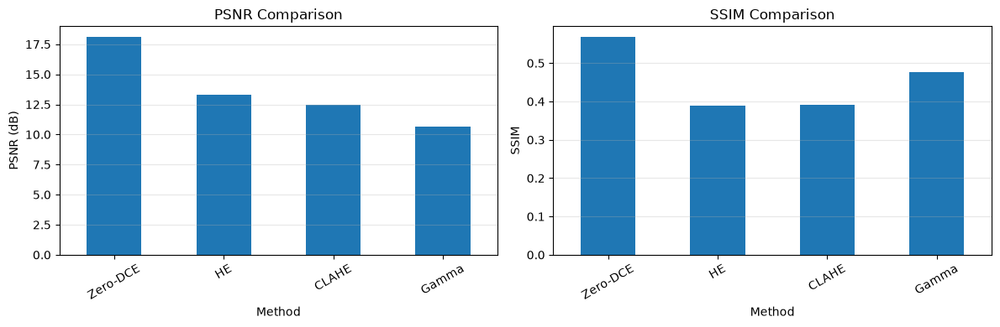

In [73]:
classical_df = pd.DataFrame.from_dict(classical_results,orient="index")
classical_df.index.name = "Method"
classical_df.to_csv(
    RES_DIR / "classical_vs_zero_dce.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
classical_df["PSNR"].plot(
    kind="bar",
    ax=axes[0],
    title="PSNR Comparison"
)

classical_df["SSIM"].plot(
    kind="bar",
    ax=axes[1],
    title="SSIM Comparison"
)

axes[0].set_ylabel("PSNR (dB)")
axes[1].set_ylabel("SSIM")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

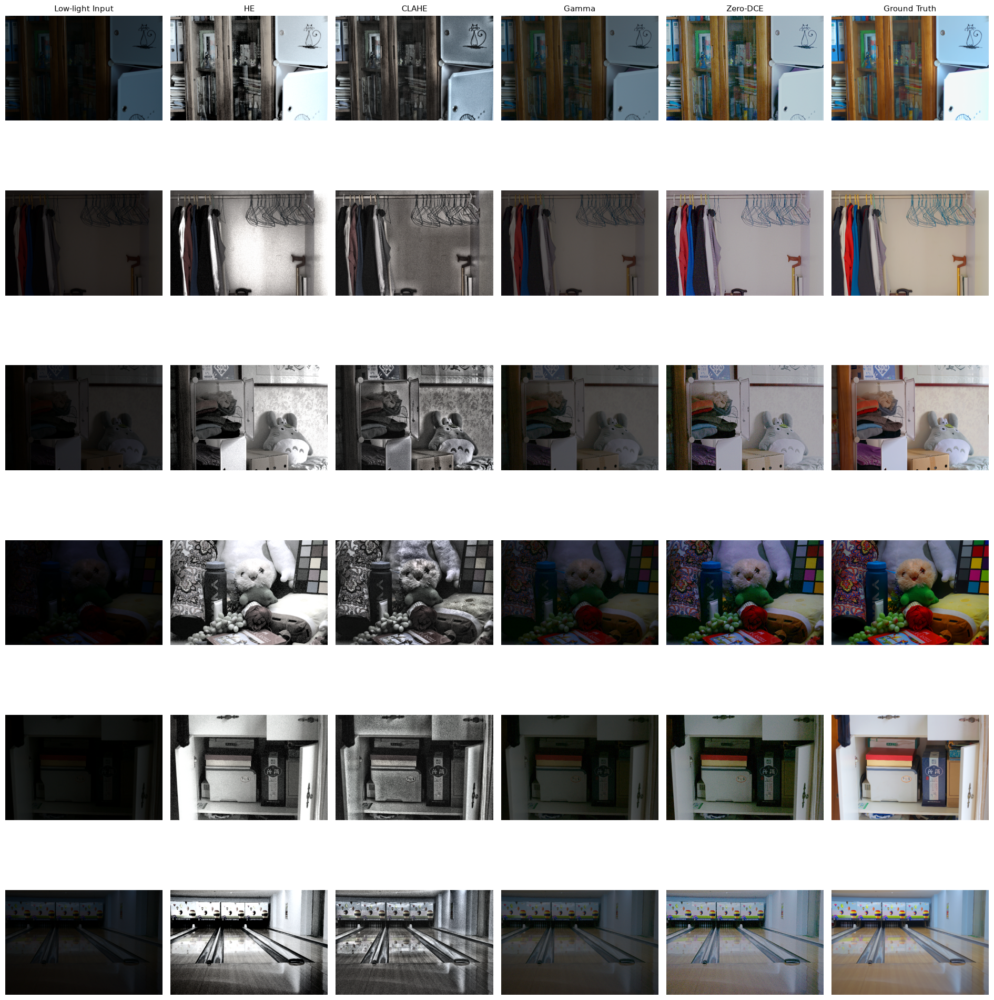

In [74]:
methods_to_show = [
    "HE",
    "CLAHE",
    "Gamma",
    "Zero-DCE"
]

indices = [0,2,4,6,8,10]

fig, axes = plt.subplots(len(indices), 6,figsize=(19, 3.5 * len(indices)),squeeze=False)
titles = [
    "Low-light Input",
    "HE",
    "CLAHE",
    "Gamma",
    "Zero-DCE",
    "Ground Truth"
]

for row, i in enumerate(indices):
    low = EVAL_LOW[i]
    high = EVAL_HIGH[i]

    images = [
        low,
        all_methods["HE"](low),
        all_methods["CLAHE"](low),
        all_methods["Gamma"](low),
        all_methods["Zero-DCE"](low),
        high
    ]

    for col, img in enumerate(images):
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(titles[col], fontsize=11)

plt.tight_layout()
plt.show()

In [83]:
MODEL_NAME = "s5_seed1_w_exp0.75_exp_target0.4_w_tv5000.0_w_spa2.0"

model = load_model(MODEL_NAME)
model.eval()

enhance = make_enhancer(model)

print("Model loaded successfully")

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

if not cap.isOpened():
    raise RuntimeError("Cannot access webcam")

WINDOW_NAME = "DCENet - Live Low Light Enhancement"

cv2.namedWindow(WINDOW_NAME, cv2.WINDOW_NORMAL)

cv2.createTrackbar(
    "Input Brightness (%)",
    WINDOW_NAME,
    100,
    200,
    lambda x: None
)


fps = 0.0
alpha = 0.1

try:
    while True:
        start = time.perf_counter()
        ret, frame = cap.read()

        if not ret:
            print("Failed to capture frame")
            break

        brightness_value = cv2.getTrackbarPos(
            "Input Brightness (%)",
            WINDOW_NAME
        )

        brightness = brightness_value / 100.0

        frame_adjusted = np.clip(
            frame.astype(np.float32) * brightness,
            0,
            255
        ).astype(np.uint8)

        frame_rgb = cv2.cvtColor(
            frame_adjusted,
            cv2.COLOR_BGR2RGB
        )

        enhanced_rgb = enhance(frame_rgb)

        enhanced = cv2.cvtColor(
            enhanced_rgb,
            cv2.COLOR_RGB2BGR
        )

        elapsed = time.perf_counter() - start

        cv2.putText(
            frame_adjusted,
            "Original",
            (15, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        cv2.putText(
            enhanced,
            "DCENet Enhanced",
            (15, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        combined = np.hstack((
            frame_adjusted,
            enhanced
        ))
        cv2.imshow(WINDOW_NAME, combined)

        # Press Q to quit
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

finally:

    cap.release()
    cv2.destroyAllWindows()

    print("Webcam stopped.")


Model loaded successfully
Webcam stopped.
